In [38]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean
import matplotlib.path as mpath
import matplotlib.pyplot as plt
import xarray as xr

In [39]:
example = "./data/five_days_ocean_velocity/soda3.15.2_5dy_ocean_reg_2018_01_03.nc"
ds = xr.open_dataset(example, engine="netcdf4", decode_timedelta=False)

In [40]:
ds

<xarray.Dataset> Size: 299MB
Dimensions:      (time: 1, st_ocean: 50, yt_ocean: 330, xt_ocean: 720,
                  sw_ocean: 50, yu_ocean: 330, xu_ocean: 720)
Coordinates:
  * time         (time) datetime64[ns] 8B 2018-01-03T13:00:00
  * st_ocean     (st_ocean) float64 400B 5.034 15.1 ... 5.185e+03 5.395e+03
  * yt_ocean     (yt_ocean) float64 3kB -74.75 -74.25 -73.75 ... 89.25 89.75
  * xt_ocean     (xt_ocean) float64 6kB 0.25 0.75 1.25 ... 358.8 359.2 359.8
  * sw_ocean     (sw_ocean) float64 400B 5.034 15.1 ... 5.185e+03 5.395e+03
  * yu_ocean     (yu_ocean) float64 3kB -74.5 -74.0 -73.5 ... 89.0 89.5 90.0
  * xu_ocean     (xu_ocean) float64 6kB 0.5 1.0 1.5 2.0 ... 359.0 359.5 360.0
Data variables: (12/22)
    temp         (time, st_ocean, yt_ocean, xt_ocean) float32 48MB ...
    salt         (time, st_ocean, yt_ocean, xt_ocean) float32 48MB ...
    wt           (time, sw_ocean, yt_ocean, xt_ocean) float32 48MB ...
    ssh          (time, yt_ocean, xt_ocean) float32 950kB ...
    mlt          (time, yt_ocean, xt_ocean) float32 950kB ...
    mlp          (time, yt_ocean, xt_ocean) float32 950kB ...
    ...           ...
    runoff       (time, yt_ocean, xt_ocean) float32 950kB ...
    u            (time, st_ocean, yu_ocean, xu_ocean) float32 48MB ...
    v            (time, st_ocean, yu_ocean, xu_ocean) float32 48MB ...
    taux         (time, yu_ocean, xu_ocean) float32 950kB ...
    tauy         (time, yu_ocean, xu_ocean) float32 950kB ...
    average_DT   (time) float32 4B ...
Attributes:
    CDI:          Climate Data Interface version 1.9.7.1 (http://mpimet.mpg.d...
    Conventions:  CF-1.6
    history:      Sat Oct 23 16:58:14 2021: cdo -f nc -b F32 copy ./mom5_regr...
    filename:     ./mom5_regrided.nc                   
    title:        MOM5_SODA_3.15.2
    grid_type:    mosaic
    grid_tile:    1
    CDO:          Climate Data Operators version 1.9.7.1 (http://mpimet.mpg.d...

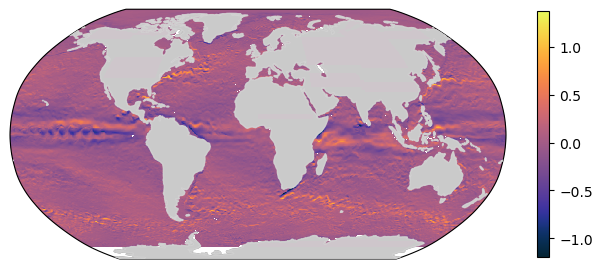

In [41]:
fig = plt.figure(figsize=(8, 8))
high_res_proj = ccrs.Robinson()
high_res_proj.threshold = 1e3
ax = fig.add_subplot(111, projection=high_res_proj)
ax.add_feature(cfeature.LAND, color="grey")
im = ax.pcolormesh(
    ds.u.isel(st_ocean=0, time=0).xu_ocean,
    ds.u.isel(st_ocean=0, time=0).yu_ocean,
    ds.u.isel(st_ocean=0, time=0).values,
    transform=ccrs.PlateCarree(),
    cmap=cmocean.cm.thermal,
    shading="nearest",
)
ax.add_feature(cfeature.LAND, color="lightgrey", alpha=0.9, zorder=10)
# ax.contour(lon, lat, depth, transform=ccrs.PlateCarree(), levels = np.linspace(-5000,0,5), colors = "k", linestyles = "solid")
plt.colorbar(im, orientation="vertical", shrink=0.4);

In [42]:
def setup_Weddell_Sea(fig):

    # Define the projection for a high-resolution South Polar Stereographic map
    high_res_proj = ccrs.SouthPolarStereo(central_longitude=-50)
    high_res_proj.threshold = 1e3

    ax = fig.add_subplot(111, projection=high_res_proj)
    ax.add_feature(cfeature.LAND, color="grey")

    # Define the limits for the x-axis and y-axis of the map
    xlim = [-80, -20]  # longitude
    ylim = [-60, -80]  # latitude

    # Define a rectangular path for the map extent using matplotlib's Path object
    rect = mpath.Path(
        [
            [xlim[0], ylim[0]],
            [xlim[1], ylim[0]],
            [xlim[1], ylim[1]],
            [xlim[0], ylim[1]],
            [xlim[0], ylim[0]],
        ]
    )

    # Transform the rectangular path to the data coordinate system
    proj_to_data = ccrs.PlateCarree()._as_mpl_transform(ax) - ax.transData
    rect_in_target = proj_to_data.transform_path(rect)

    # Set the boundary of the map using the transformed rectangular path
    ax.set_boundary(rect_in_target)

    # Configure gridlines for the map
    gl = ax.gridlines(draw_labels=["top", "right", "x", "y"], rotate_labels=True, x_inline=False)

    # Draw latitude and longitude gridlines (and their labels)
    # only at the specified values
    """
    lathelp = np.arange(-75, -60, 5)
    gl.ylocator = mticker.FixedLocator(lathelp)
    lonhelp = np.arange(-80, -10, 10)
    gl.xlocator = mticker.FixedLocator(lonhelp)
    """

    # Rotate the longitude labels to be more readable
    gl.xlabel_style = {"rotation": 30}

    # To make sure that all of the wanted map extent is visible in the figure,
    # (especially because the chosen map projections differs strongly
    # at the poles from the PlateCarree Projection)
    # this hack of adding a constant is needed and may need be adjusted,
    # dependent on your map extent and figure size
    ax.set_extent([xlim[0], xlim[1], ylim[0] + 4, ylim[1]])

    return ax

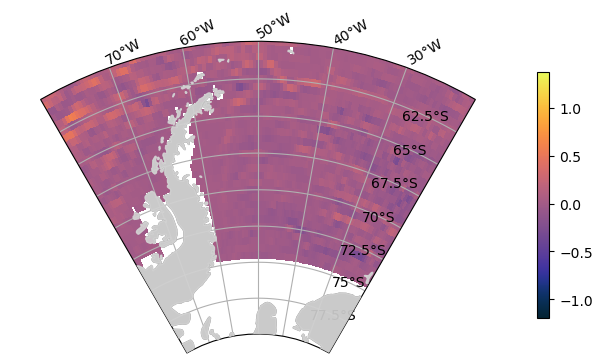

In [43]:
fig = plt.figure(figsize=(8, 8))
ax = setup_Weddell_Sea(fig)
im = ax.pcolormesh(
    ds.u.isel(st_ocean=0, time=0).xu_ocean,
    ds.u.isel(st_ocean=0, time=0).yu_ocean,
    ds.u.isel(st_ocean=0, time=0).values,
    transform=ccrs.PlateCarree(),
    cmap=cmocean.cm.thermal,
    shading="nearest",
)
ax.add_feature(cfeature.LAND, color="lightgrey", alpha=0.9, zorder=10)
# ax.contour(lon, lat, depth, transform=ccrs.PlateCarree(), levels = np.linspace(-5000,0,5), colors = "k", linestyles = "solid")
plt.colorbar(im, orientation="vertical", shrink=0.4);

# Read out data for all months

In [44]:
from dask.distributed import Client, LocalCluster

cluster = LocalCluster(n_workers=4, threads_per_worker=4)
client = Client(cluster)
client

/albedo/soft/sw/conda-sw/analysis-toolbox-python-04.2026/lib/python3.12/site-packages/distributed/node.py:188: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 38893 instead
  warnings.warn(


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:38893/status,
Dashboard: http://127.0.0.1:38893/status,Workers: 4
Total threads: 16,Total memory: 32.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:42981,Workers: 0
Dashboard: http://127.0.0.1:38893/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:35081,Total threads: 4
Dashboard: http://127.0.0.1:44745/status,Memory: 8.00 GiB
Nanny: tcp://127.0.0.1:37307,


In [45]:
def preprocess(ds):
    ds = ds[["u", "v"]]  # , "taux", "tauy"]]
    return ds.isel(st_ocean=slice(0, 2)).mean("st_ocean")


surface_velocity = xr.open_mfdataset(
    "./data/five_days_ocean_velocity/soda3.15.2_5dy_ocean_reg_*.nc",
    combine="by_coords",
    parallel=True,
    chunks={"time": 1, "xu_ocean": 200, "yu_ocean": 200, "st_ocean": 5},
    preprocess=preprocess,
    data_vars="minimal",
    coords="minimal",
    compat="override",
)

In [46]:
surface_velocity = surface_velocity.chunk(chunks={"time": -1, "xu_ocean": 300, "yu_ocean": -1})
surface_velocity

<xarray.Dataset> Size: 287MB
Dimensions:   (time: 151, yu_ocean: 330, xu_ocean: 720)
Coordinates:
  * time      (time) datetime64[ns] 1kB 2017-01-03T13:00:00 ... 2019-01-23T13...
  * yu_ocean  (yu_ocean) float64 3kB -74.5 -74.0 -73.5 -73.0 ... 89.0 89.5 90.0
  * xu_ocean  (xu_ocean) float64 6kB 0.5 1.0 1.5 2.0 ... 358.5 359.0 359.5 360.0
Data variables:
    u         (time, yu_ocean, xu_ocean) float32 144MB dask.array<chunksize=(151, 330, 300), meta=np.ndarray>
    v         (time, yu_ocean, xu_ocean) float32 144MB dask.array<chunksize=(151, 330, 300), meta=np.ndarray>
Attributes:
    CDI:          Climate Data Interface version 1.9.7.1 (http://mpimet.mpg.d...
    Conventions:  CF-1.6
    history:      Fri Oct 22 15:31:36 2021: cdo -f nc -b F32 copy ./mom5_regr...
    filename:     ./mom5_regrided.nc                   
    title:        MOM5_SODA_3.15.2
    grid_type:    mosaic
    grid_tile:    1
    CDO:          Climate Data Operators version 1.9.7.1 (http://mpimet.mpg.d...

In [47]:
# coordinate wrangling
surface_velocity = surface_velocity.rename({"xu_ocean": "longitude", "yu_ocean": "latitude"})
surface_velocity.coords["longitude"] = (surface_velocity.coords["longitude"] + 180) % 360 - 180
surface_velocity = surface_velocity.sortby(surface_velocity.longitude)
surface_velocity.coords["time"] = surface_velocity.coords["time"].dt.floor(
    "D"
)  # round to nearest day

In [48]:
# cut to Weddell Sea
surface_velocity = surface_velocity.sel(latitude=slice(-90, -50), longitude=slice(-90, -10))

In [49]:
surface_velocity

<xarray.Dataset> Size: 10MB
Dimensions:    (time: 151, latitude: 50, longitude: 161)
Coordinates:
  * time       (time) datetime64[ns] 1kB 2017-01-03 2017-01-08 ... 2019-01-23
  * latitude   (latitude) float64 400B -74.5 -74.0 -73.5 ... -51.0 -50.5 -50.0
  * longitude  (longitude) float64 1kB -90.0 -89.5 -89.0 ... -11.0 -10.5 -10.0
Data variables:
    u          (time, latitude, longitude) float32 5MB dask.array<chunksize=(151, 50, 60), meta=np.ndarray>
    v          (time, latitude, longitude) float32 5MB dask.array<chunksize=(151, 50, 60), meta=np.ndarray>
Attributes:
    CDI:          Climate Data Interface version 1.9.7.1 (http://mpimet.mpg.d...
    Conventions:  CF-1.6
    history:      Fri Oct 22 15:31:36 2021: cdo -f nc -b F32 copy ./mom5_regr...
    filename:     ./mom5_regrided.nc                   
    title:        MOM5_SODA_3.15.2
    grid_type:    mosaic
    grid_tile:    1
    CDO:          Climate Data Operators version 1.9.7.1 (http://mpimet.mpg.d...

In [50]:
surface_velocity.compute().to_zarr("surface_stress_ocean_velocity.zarr", mode="w")

/albedo/soft/sw/conda-sw/analysis-toolbox-python-04.2026/lib/python3.12/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
